# EN3160 Assignment 2 – Fitting and Alignment
**Name:** Prishmika H>W.N  **Index:** 230500N  
**GitHub:** <https://github.com/Nimindu04/EN3160_Assignment_02>

## Q1 – Blob detection with scale-normalised LoG

Candidates after thresholding: 63
Final detections: 52


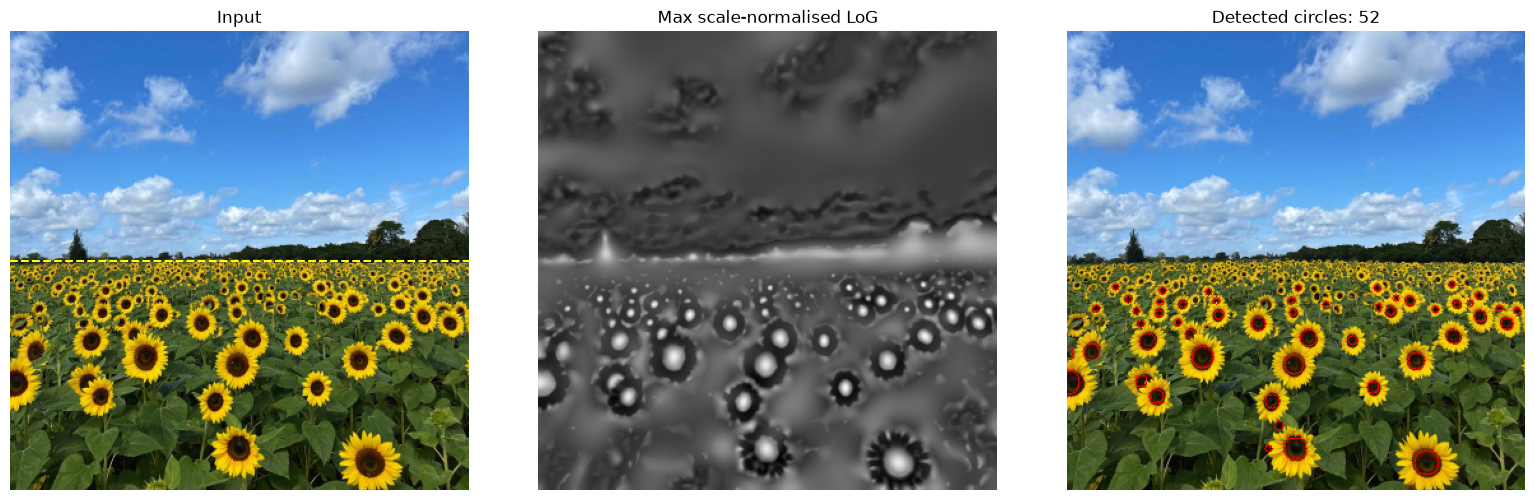


Sigma range: 2.00 - 16.27 (16 scales, ratio 1.15)
Largest circles:
1. centre=(282, 338), r=9.95 px, sigma=7.04, response=89.0
2. centre=(0, 275), r=9.95 px, sigma=7.04, response=87.7
3. centre=(106, 255), r=8.65 px, sigma=6.12, response=92.1
4. centre=(179, 327), r=8.65 px, sigma=6.12, response=87.8
5. centre=(178, 261), r=7.52 px, sigma=5.32, response=88.9
6. centre=(189, 240), r=6.54 px, sigma=4.63, response=92.2
7. centre=(63, 243), r=6.54 px, sigma=4.63, response=89.9
8. centre=(274, 258), r=6.54 px, sigma=4.63, response=87.9
9. centre=(19, 251), r=6.54 px, sigma=4.63, response=74.1
10. centre=(303, 239), r=5.69 px, sigma=4.02, response=97.0


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

DIR = 'a2images'
# Load the image 
image_path = f'{DIR}/the_berry_farms_sunflower_field.jpeg'
im = cv.imread(image_path, cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError(f"Image not found: {image_path}")
im_rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(im_rgb, cv.COLOR_RGB2GRAY).astype(np.float32)

# Parameters
k = 1.15                                   # scale ratio between neighbouring sigmas
sigma_min, sigma_max = 2.0, 18.0
n_scales = int(np.log(sigma_max / sigma_min) / np.log(k)) + 1
sigmas = sigma_min * k ** np.arange(n_scales)     # 2.0 ... ~16.3
threshold = 60.0                           # on sigma^2 * LoG (dark blobs)
horizon_y = 180                            

# Scale-normalised LoG, signed.
responses = np.stack([
    (s ** 2) * cv.Laplacian(cv.GaussianBlur(gray, (0, 0), float(s)), cv.CV_32F, ksize=1)
    for s in sigmas
])

# Scale-space extrema (3x3x3) above threshold
local_max = maximum_filter(responses, size=(3, 3, 3), mode="nearest")
si, ys, xs = np.where((responses == local_max) & (responses >= threshold))
strengths = responses[si, ys, xs]
print("Candidates after thresholding:", len(strengths))

# Keep only the field region
keep = ys > horizon_y
si, ys, xs, strengths = si[keep], ys[keep], xs[keep], strengths[keep]


radii = np.sqrt(2.0) * sigmas[si]

# Non-maximum suppression (strongest first, drop overlapping centres)
accepted = []
for i in np.argsort(strengths)[::-1]:
    c = dict(x=int(xs[i]), y=int(ys[i]), radius=float(radii[i]),
             sigma=float(sigmas[si[i]]), strength=float(strengths[i]))
    if all(np.hypot(c["x"] - p["x"], c["y"] - p["y"]) >= max(c["radius"], p["radius"])
           for p in accepted):
        accepted.append(c)
print("Final detections:", len(accepted))

#  Plot the results
result = im_rgb.copy()
for d in accepted:
    cv.circle(result, (d["x"], d["y"]), max(2, int(round(d["radius"]))), (255, 0, 0), 1)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(im_rgb); ax[0].axhline(horizon_y, color="yellow", ls="--"); ax[0].set_title("Input")
ax[1].imshow(responses.max(axis=0), cmap="gray"); ax[1].set_title("Max scale-normalised LoG")
ax[2].imshow(result); ax[2].set_title(f"Detected circles: {len(accepted)}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# Step 9: Report 10 largest circles
print(f"\nSigma range: {sigmas[0]:.2f} - {sigmas[-1]:.2f} ({len(sigmas)} scales, ratio {k})")
print("Largest circles:")
for i, d in enumerate(sorted(accepted, key=lambda d: -d["radius"])[:10], 1):
    print(f"{i}. centre=({d['x']}, {d['y']}), r={d['radius']:.2f} px, "
          f"sigma={d['sigma']:.2f}, response={d['strength']:.1f}")

### Q1 – Results

**Method.** The image was loaded with IMREAD_REDUCED_COLOR_4 (360×360) and converted to grayscale. Scale-normalised LoG responses σ²·∇²(G_σ * I) were computed for **σ = 2.0 to 16.27** (16 scales, geometric ratio 1.15). Sunflower centres are dark blobs, so the signed response is kept (positive peaks). A 3×3×3 local maximum in (scale, y, x) with response ≥ 60 marks a blob, with radius r = √2·σ. Detections above the field (y ≤ 180) were discarded and overlapping centres suppressed. `cv2.HoughCircles` was not used.

**Result**  A total of 63 candidate blobs were detected, and 52 circles remained after filtering.

| # | Centre (x, y) | Radius (px) | σ |
|---|---------------|-------------|---|
| 1 | (282, 338) | 9.95 | 7.04 |
| 2 | (0, 275)   | 9.95 | 7.04 |
| 3 | (106, 255) | 8.65 | 6.12 |
| 4 | (179, 327) | 8.65 | 6.12 |
| 5 | (178, 261) | 7.52 | 5.32 |

**Discussion.** The circles mark the dark seed discs. The largest circles are on the nearest flowers at the bottom, and radii shrink towards the horizon, which matches perspective. Distant, tiny flowers and heavily overlapped ones are missed. Using the signed response removed the extra circles on petals that |LoG| produced.

## Q2 – RANSAC line and circle fitting

In [2]:
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize
DIR = 'a2images'
np.random.seed(0)
N = 100; half_n = N//2; r = 10; x0_gt, y0_gt = 2, 3; s = r/16
t = np.random.uniform(0, 2*np.pi, half_n); n = s*np.random.randn(half_n)
x, y = x0_gt + (r+n)*np.cos(t), y0_gt + (r+n)*np.sin(t)
X_circ = np.column_stack((x, y))
s = 1.; m, b = -1, 2
x = np.linspace(-12, 12, half_n); y = m*x + b + s*np.random.randn(half_n)
X_line = np.column_stack((x, y)); X = np.vstack((X_circ, X_line))

### (a) Line with RANSAC

RANSAC fits a line using two random points. The perpendicular distance threshold is 1.5, and at least 30 inliers are required. The final line is refitted using SVD on the inliers.

In [3]:
def line_from_2pts(p, q):
    d = q - p; nrm = np.array([-d[1], d[0]]); nrm /= np.linalg.norm(nrm)
    return nrm[0], nrm[1], nrm @ p
def line_err(l, P): return np.abs(P @ np.array(l[:2]) - l[2])
def tls_line(P):
    mu = P.mean(0); _, _, Vt = np.linalg.svd(P - mu); nrm = Vt[1]
    return nrm[0], nrm[1], nrm @ mu

def ransac_line(X, thr=1.5, min_inl=30, iters=500):
    best = (None, None, 0, None)
    for _ in range(iters):
        i = np.random.choice(len(X), 2, replace=False)
        l = line_from_2pts(X[i[0]], X[i[1]]); inl = line_err(l, X) < thr
        if inl.sum() > best[2]: best = (l, inl, inl.sum(), i)
    assert best[2] >= min_inl, 'no consensus'
    return best

l0, inl_l, cnt, samp_l = ransac_line(X)
lbest = tls_line(X[inl_l])
print('best-sample line (a,b,d):', np.round(l0, 3), '| inliers:', cnt)
print('refit line (a,b,d):', np.round(lbest, 3), '| norm =', np.hypot(*lbest[:2]))
print('ground truth y=-x+2  ->  (a,b,d) = (0.707, 0.707, 1.414) up to sign')

best-sample line (a,b,d): [-0.7   -0.714 -1.637] | inliers: 56
refit line (a,b,d): [0.718 0.696 1.522] | norm = 1.0
ground truth y=-x+2  ->  (a,b,d) = (0.707, 0.707, 1.414) up to sign


### (b) Circle with RANSAC on the Remnant

Three points define a candidate circle. The radial error threshold is 1.5, with at least 20 inliers required. The best circle is refined using BFGS to minimise the sum of squared radial errors.

In [4]:
def circle_from_3pts(p1, p2, p3):
    A = np.array([2*(p2-p1), 2*(p3-p1)]); B = np.array([p2@p2 - p1@p1, p3@p3 - p1@p1])
    if abs(np.linalg.det(A)) < 1e-9: return None
    c = np.linalg.solve(A, B); return c[0], c[1], np.linalg.norm(p1 - c)
def circ_err(c, P): return np.abs(np.hypot(P[:,0]-c[0], P[:,1]-c[1]) - c[2])
def fit_circle(P, init):
    f = lambda c: np.sum((np.hypot(P[:,0]-c[0], P[:,1]-c[1]) - c[2])**2)
    return minimize(f, init, method='BFGS').x

def ransac_circle(R, thr=1.5, min_inl=20, iters=1000):
    best = (None, None, 0, None)
    for _ in range(iters):
        i = np.random.choice(len(R), 3, replace=False); c = circle_from_3pts(*R[i])
        if c is None or c[2] > 30: continue
        inl = circ_err(c, R) < thr
        if inl.sum() > best[2]: best = (c, inl, inl.sum(), i)
    assert best[2] >= min_inl, 'no consensus'
    return best

R = X[~inl_l]                                   # remove line consensus
c0, inl_c, cc, samp_c = ransac_circle(R)
cbest = fit_circle(R[inl_c], c0)
print('best-sample circle (x,y,r):', np.round(c0, 3), '| inliers:', cc)
print('refit circle (x,y,r):', np.round(cbest, 3), '| ground truth', (x0_gt, y0_gt, r))

best-sample circle (x,y,r): [ 1.98   3.391 10.133] | inliers: 44
refit circle (x,y,r): [1.868 3.067 9.949] | ground truth (2, 3, 10)


### (c) Combined plot

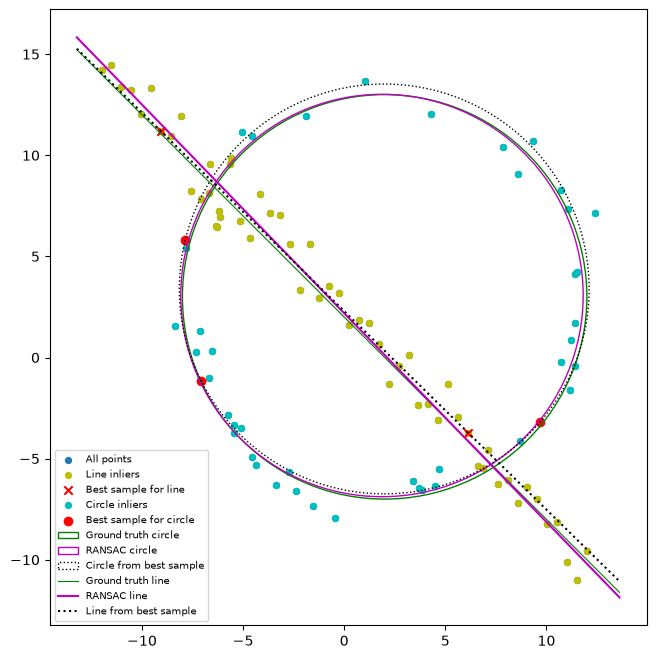

In [5]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(*X.T, s=18, label='All points')
ax.scatter(*X[inl_l].T, s=18, c='y', label='Line inliers')
ax.scatter(*X[samp_l].T, marker='x', c='r', label='Best sample for line')
ax.scatter(*R[inl_c].T, s=18, c='c', label='Circle inliers')
ax.scatter(*R[samp_c].T, c='r', label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(cbest[:2], cbest[2], color='m', fill=False, label='RANSAC circle'))
ax.add_patch(plt.Circle(c0[:2], c0[2], color='k', fill=False, ls=':', label='Circle from best sample'))
xs = np.array(ax.get_xlim())
ax.plot(xs, m*xs + b, 'g', lw=.8, label='Ground truth line')
ax.plot(xs, (lbest[2] - lbest[0]*xs)/lbest[1], 'm', label='RANSAC line')
a_, b_, d_ = l0; ax.plot(xs, (d_ - a_*xs)/b_, 'k:', label='Line from best sample')
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

### (c) Comment on the plot

The RANSAC line (magenta) and RANSAC circle (magenta) lie very close to the ground truth (green). The dotted curves are the models from the best minimal samples; they are slightly off (circle centre y = 3.39 vs 3.07 after refit), which shows why the consensus refit is used. Line inliers (yellow) and circle inliers (cyan) overlap only near the two crossings.

### (d) What if the circle is fitted first?

When the circle is fitted first using all 100 points, RANSAC finds **60 inliers: 50 circle points and 10 line points**. The fitted circle parameters, (1.979, 2.966, 9.958), are still close to the true values. Therefore, the circle fit is not affected much.

However, 10 line points near the circle crossings are also removed. As a result, only 40 of the original 50 line points remain for fitting the line.

Since both the circle and the line have 50 points, fitting the circle first works reasonably well in this case. However, points from the other shape can affect the fitting result. Fitting the line first is safer because fewer circle points fall within the line's inlier band.

In [6]:
np.random.seed(1)
c1, inl1, cn1, _ = ransac_circle(X)
print('circle-first inliers:', cn1, '| true circle pts:', inl1[:half_n].sum(), '| line pts:', inl1[half_n:].sum())
print('circle (x,y,r):', np.round(fit_circle(X[inl1], c1), 3))

circle-first inliers: 60 | true circle pts: 50 | line pts: 10
circle (x,y,r): [1.979 2.966 9.958]


## Q3 – Planar homography: superimposing the flag

wadham.jpg H =
 [[2.6170e-01 0.0000e+00 1.4720e+02]
 [7.4000e-02 2.3470e-01 2.0736e+02]
 [1.0000e-04 0.0000e+00 1.0000e+00]]
pcbs/AECC1.jpg H =
 [[ 5.445000e-01 -7.726000e-01  9.965870e+02]
 [ 2.043000e-01  2.016900e+00  2.116041e+02]
 [-0.000000e+00 -0.000000e+00  1.000000e+00]]
pcbs/ADAD1.jpg H =
 [[ 4.739000e-01 -6.341000e-01  8.605852e+02]
 [ 1.598000e-01  2.050100e+00  1.652324e+02]
 [-0.000000e+00  0.000000e+00  1.000000e+00]]


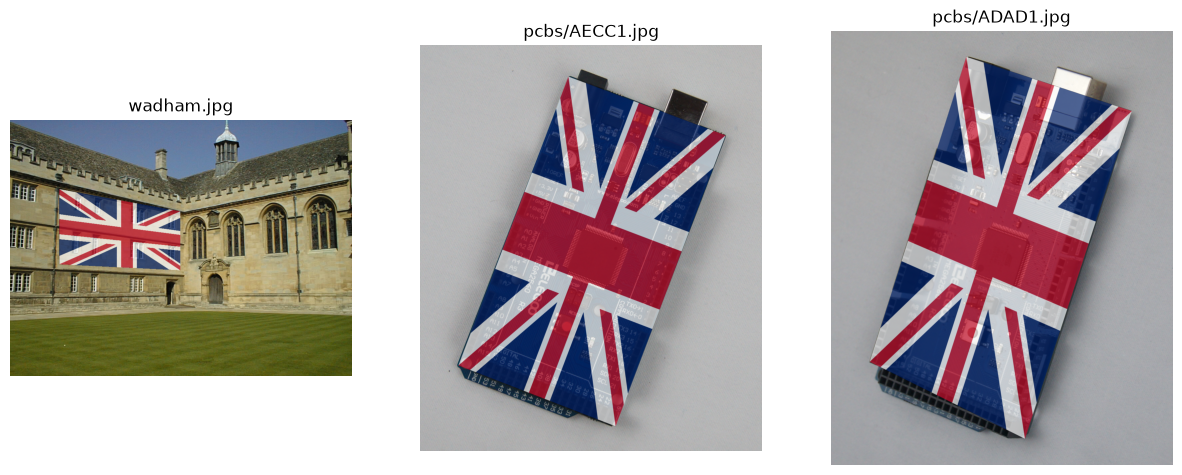

In [7]:
flag = cv.imread(f'{DIR}/flag.png'); fh, fw = flag.shape[:2]
src = np.float32([[0,0],[fw,0],[fw,fh],[0,fh]])

def superimpose(base, pts, alpha=0.7):
    H, _ = cv.findHomography(src, np.float32(pts))
    h, w = base.shape[:2]
    warped = cv.warpPerspective(flag, H, (w, h))
    mask = cv.warpPerspective(np.full((fh, fw), 255, np.uint8), H, (w, h)) > 0
    out = np.where(mask[..., None], (alpha*warped + (1-alpha)*base).astype(np.uint8), base)
    return out, H

# corners (TL, TR, BR, BL) were read off a downscaled preview; sc rescales to full resolution
sets = [('wadham.jpg',        1.28,      [(115,162),(398,214),(398,352),(115,338)]),
        ('pcbs/AECC1.jpg',    1/0.293,   [(292,62),(602,178),(385,752),(75,632)]),
        ('pcbs/ADAD1.jpg',    1/0.2905,  [(250,48),(555,148),(358,752),(72,610)])]
fig, ax = plt.subplots(1, 3, figsize=(15,6))
for a, (f, sc, p) in zip(ax, sets):
    im = cv.imread(f'{DIR}/{f}'); out, H = superimpose(im, [(px*sc, py*sc) for px, py in p])
    print(f, 'H =\n', np.round(H, 4))
    a.imshow(out[:, :, ::-1]); a.axis('off'); a.set_title(f)
plt.show()

**Notes:** The flag is stretched to fit the PCB, changing its aspect ratio. To avoid distortion, use a rectangle with the flag's original ratio. Accurate facade corners are also important, as small errors in the top and bottom lines can skew the flag.

### Q3 – Results

Four corners were picked manually on each target plane, and the homography H from the flag corners to these points was computed with `cv.findHomography`. The flag is warped with `warpPerspective` and alpha-blended (α = 0.7) inside the warped quadrilateral.

**Image choices** I used the Wadham College image for comparison with the example in the handout, and two PCB images (AECC1, ADAD1) because the board is a flat rectangle with sharp edges, so the four corners are easy to place accurately, and these are the same images used in Q4.

| Image | H (rounded) |
|---|---|
| wadham.jpg | [[0.2617, 0, 147.20], [0.0740, 0.2347, 207.36], [1e-4, 0, 1]] |
| AECC1.jpg | [[0.5445, −0.7726, 996.59], [0.2043, 2.0169, 211.60], [0, 0, 1]] |
| ADAD1.jpg | [[0.4739, −0.6341, 860.59], [0.1598, 2.0501, 165.23], [0, 0, 1]] |

**Observations.** On the PCBs the flag follows the board outline and its perspective foreshortening. On the college wall it follows the receding facade. The flag is stretched to the quadrilateral, so its aspect ratio changes; picking a rectangle with the flag's own ratio would avoid this. Small errors in the corner positions skew the flag, most visibly along the long edges.

## Q4 – PCB alignment with SIFT + RANSAC homography

In [8]:
tpl = cv.imread(f'{DIR}/pcbs/AECC1.jpg'); tg = cv.cvtColor(tpl, cv.COLOR_BGR2GRAY)
sift = cv.SIFT_create(nfeatures=8000)
k1, d1 = sift.detectAndCompute(tg, None)
names = ['AECC2', 'AECC3', 'AECC4', 'ADAD1', 'AAAA1']
res = {}
for n in names:
    im = cv.imread(f'{DIR}/pcbs/{n}.jpg'); g = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
    k2, d2 = sift.detectAndCompute(g, None)
    mt = cv.BFMatcher().knnMatch(d2, d1, k=2)
    good = [a for a, b2 in mt if a.distance < 0.75*b2.distance]
    s_ = np.float32([k2[m.queryIdx].pt for m in good]); d_ = np.float32([k1[m.trainIdx].pt for m in good])
    H, mask = cv.findHomography(s_, d_, cv.RANSAC, 5.0)
    warped = cv.warpPerspective(im, H, (tpl.shape[1], tpl.shape[0]))
    diff = cv.absdiff(cv.cvtColor(warped, cv.COLOR_BGR2GRAY), tg)
    dm = cv.drawMatches(im, k2, tpl, k1, [m for m, k in zip(good, mask.ravel()) if k][:80], None, flags=2)
    res[n] = (dm, warped, diff)
    print(f'{n}: good matches {len(good)}, RANSAC inliers {int(mask.sum())}, mean |diff| {diff.mean():.1f}')

AECC2: good matches 3214, RANSAC inliers 2827, mean |diff| 5.7
AECC3: good matches 3948, RANSAC inliers 3549, mean |diff| 4.6
AECC4: good matches 2905, RANSAC inliers 2550, mean |diff| 6.1
ADAD1: good matches 357, RANSAC inliers 190, mean |diff| 33.9
AAAA1: good matches 75, RANSAC inliers 11, mean |diff| 55.0


### (b) Matches (RANSAC inliers, first 80 drawn)

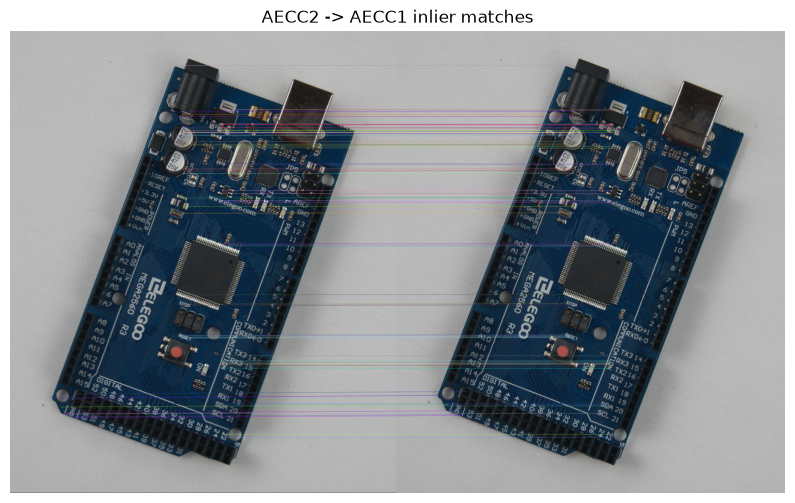

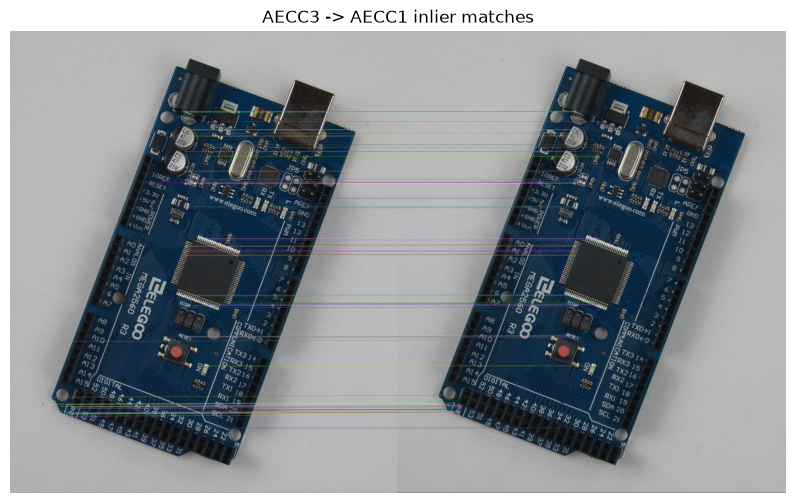

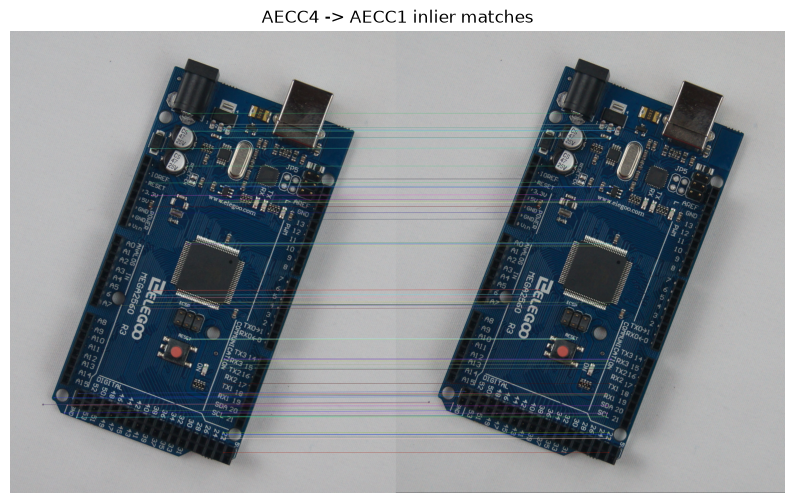

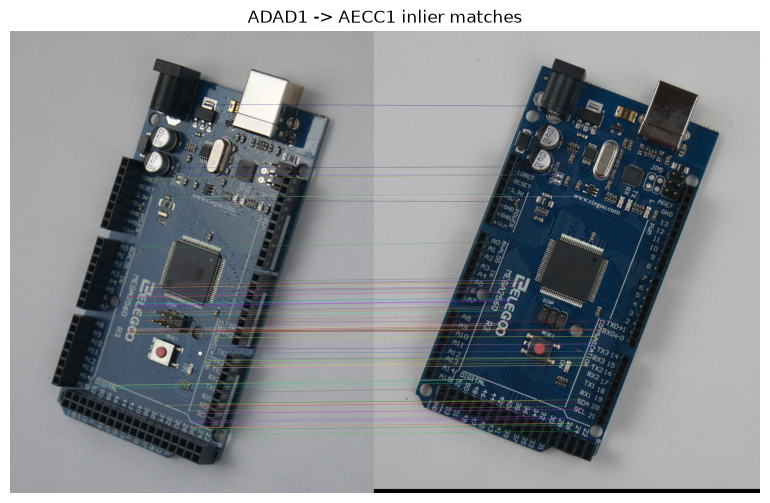

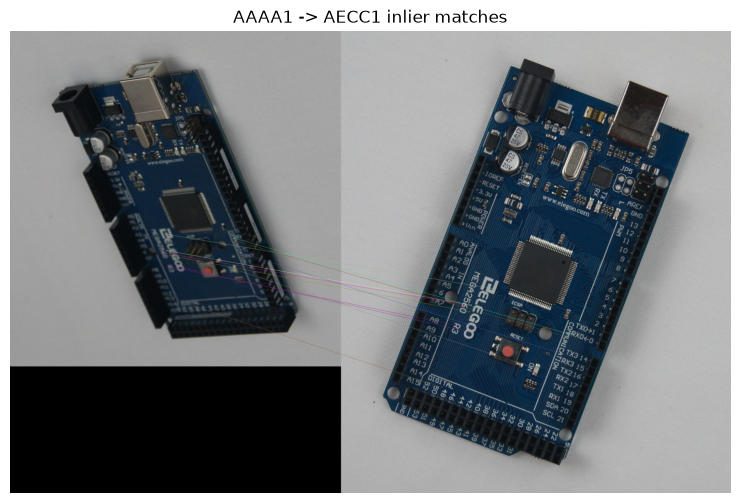

In [9]:
for n in names:
    plt.figure(figsize=(12,6)); plt.imshow(res[n][0][:, :, ::-1]); plt.axis('off'); plt.title(f'{n} -> AECC1 inlier matches'); plt.show()

### (c, d) Aligned images and difference images

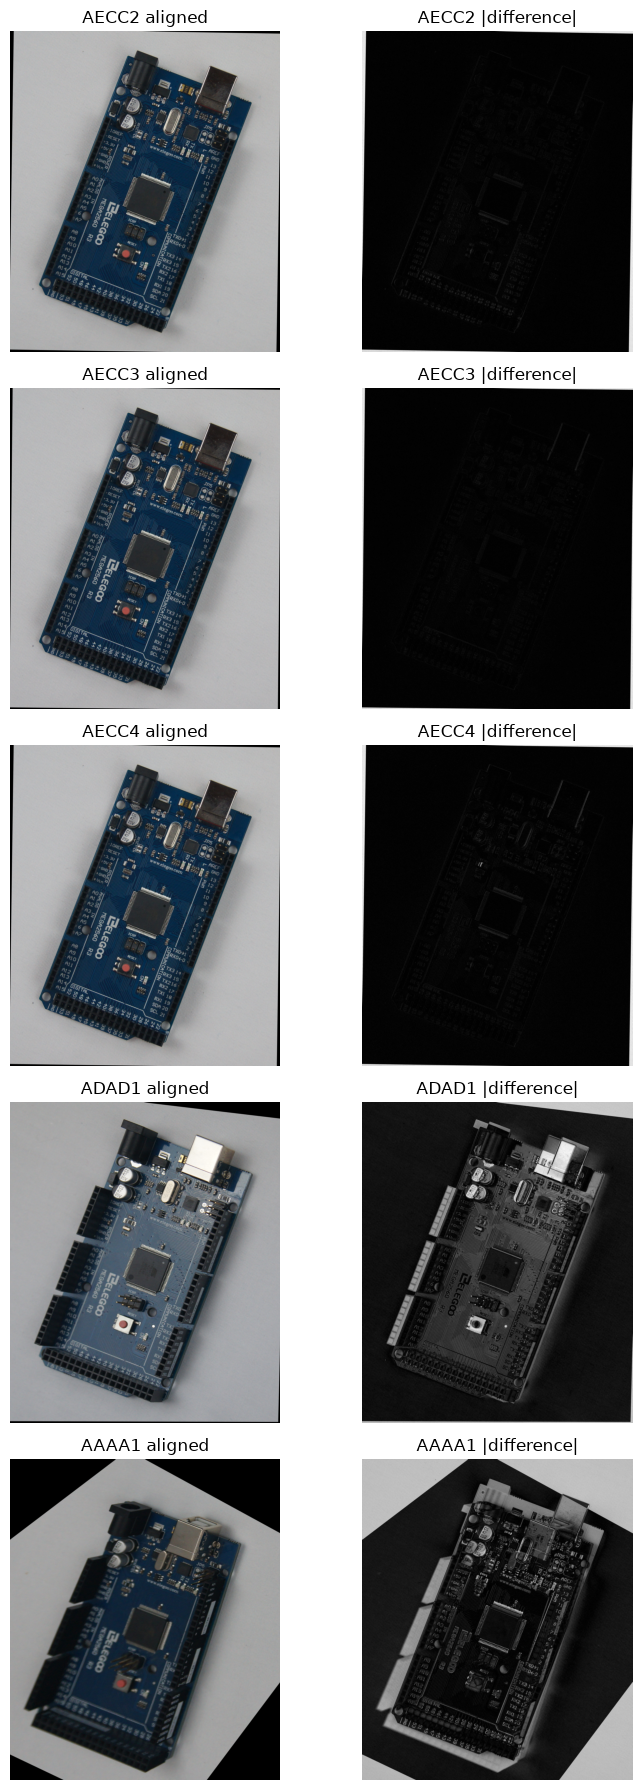

In [10]:
fig, ax = plt.subplots(len(names), 2, figsize=(8, 3.6*len(names)))
for i, n in enumerate(names):
    ax[i,0].imshow(res[n][1][:, :, ::-1]); ax[i,0].set_title(n + ' aligned')
    ax[i,1].imshow(res[n][2], cmap='gray');  ax[i,1].set_title(n + ' |difference|')
    for a in ax[i]: a.axis('off')
plt.tight_layout(); plt.show()

### (e) Why do the USB-B port, capacitors and reset button differ strongly?

A homography works well only for points on the same flat plane, which is the PCB surface in this case. The USB-B port, capacitors and reset button are raised above the board. When the camera moves, these parts shift relative to the PCB due to parallax, so the same homography cannot align them correctly.

Their shiny surfaces also reflect light differently depending on the camera angle and lighting. Shadows, lens distortion and keypoint detection errors also contribute to the differences. Flat features, such as printed text and PCB traces, align well, so they appear darker in the difference image.